In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


Total sketches: 3
01_two_storey_house.png (520, 690)


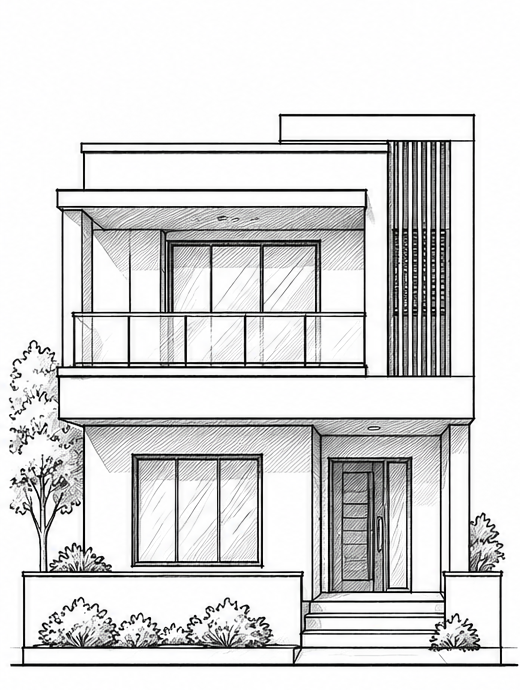

02_apartment_facade.png (495, 690)


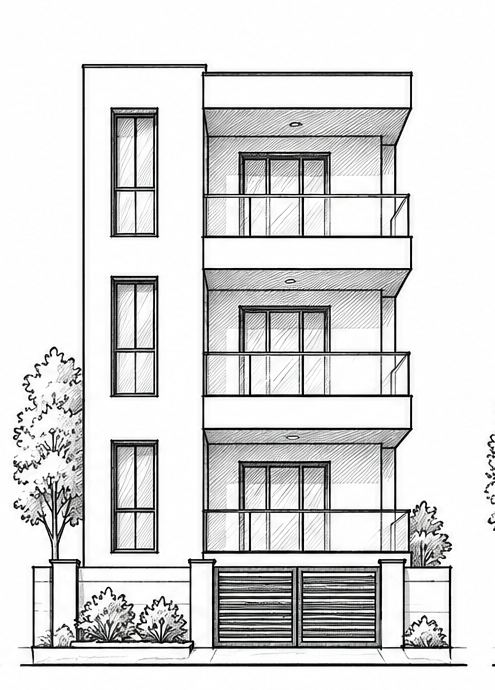

03_modern_villa.png (521, 690)


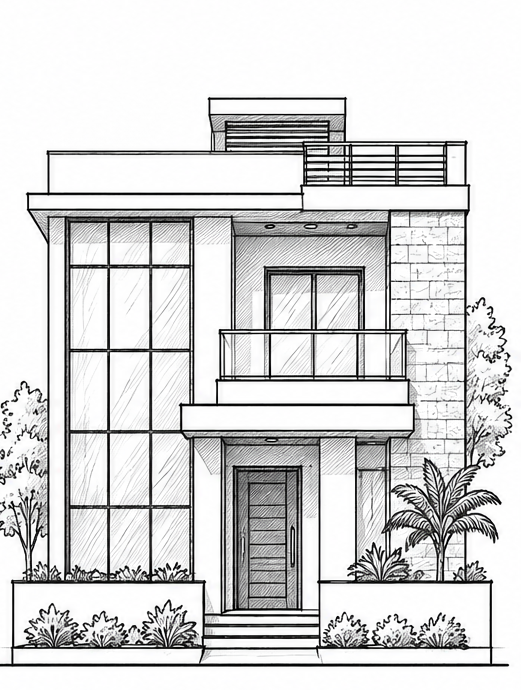

In [1]:
import zipfile
import os
from PIL import Image
from IPython.display import display

zip_path = "/content/FacadeForge_AI_sample_sketches.zip"
extract_path = "/content/facade_sketches"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

sketches = sorted(os.listdir(extract_path))

print("Total sketches:", len(sketches))

for sketch in sketches:
    image = Image.open(os.path.join(extract_path, sketch))
    print(sketch, image.size)
    display(image)

In [2]:
!pip install -q diffusers transformers accelerate safetensors

In [3]:
import torch
import diffusers
import transformers

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Diffusers: 0.42.1
Transformers: 5.22.1
GPU: Tesla T4
CUDA: True


In [4]:
import torch
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline
)
from transformers import CLIPTextModel

print("ControlNet imports: SUCCESS")
print("Stable Diffusion pipeline: SUCCESS")
print("CLIP imports: SUCCESS")
print("GPU:", torch.cuda.get_device_name(0))

ControlNet imports: SUCCESS
Stable Diffusion pipeline: SUCCESS
CLIP imports: SUCCESS
GPU: Tesla T4


In [5]:
import torch
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline,
    DPMSolverMultistepScheduler
)

BASE_MODEL = "runwayml/stable-diffusion-v1-5"
CONTROLNET_MODEL = "lllyasviel/sd-controlnet-canny"

print("Loading ControlNet...")

controlnet = ControlNetModel.from_pretrained(
    CONTROLNET_MODEL,
    torch_dtype=torch.float16,
    use_safetensors=True
)

print("Loading Stable Diffusion...")

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    BASE_MODEL,
    controlnet=controlnet,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()
pipe.enable_vae_slicing()

print("Both models loaded successfully!")

Loading ControlNet...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

Loading Stable Diffusion...


... (4 outputs left out)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

AttributeError: 'StableDiffusionControlNetPipeline' object has no attribute 'enable_vae_slicing'

In [6]:
# Apply memory optimizations supported by this pipeline

pipe.enable_attention_slicing()

# VAE slicing is optional; enable only if supported
if hasattr(pipe, "enable_vae_slicing"):
    pipe.enable_vae_slicing()
    print("VAE slicing enabled")
else:
    print("VAE slicing unavailable - skipping")

print("GPU:", torch.cuda.get_device_name(0))
print("Pipeline ready!")

VAE slicing unavailable - skipping
GPU: Tesla T4
Pipeline ready!


In [7]:
import os
from glob import glob
from PIL import Image

SKETCH_DIR = "/content/facade_sketches"
OUTPUT_DIR = "/content/facadeforge_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

sketch_paths = sorted(
    glob(os.path.join(SKETCH_DIR, "*.png"))
)

print("Available sketches:", len(sketch_paths))

for path in sketch_paths:
    print(os.path.basename(path))

Available sketches: 3
01_two_storey_house.png
02_apartment_facade.png
03_modern_villa.png


Original sketch:


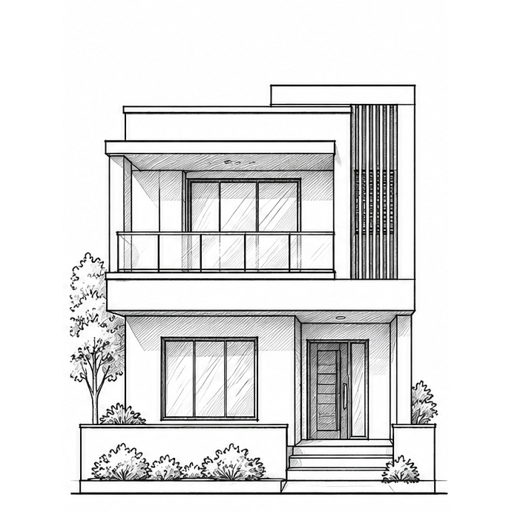

ControlNet edge map:


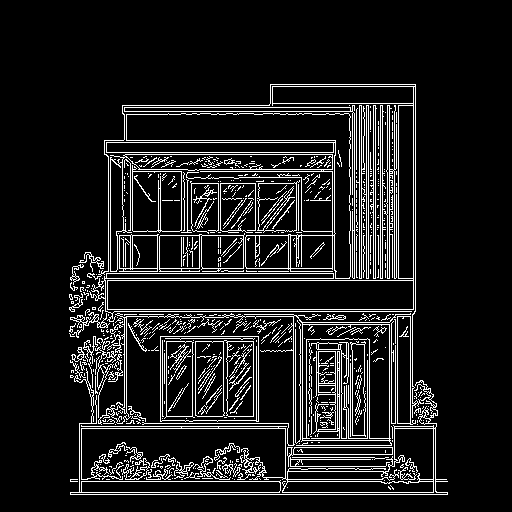

In [8]:
import cv2
import numpy as np
from PIL import Image, ImageOps
from IPython.display import display

def prepare_sketch(image_path):

    image = Image.open(image_path).convert("RGB")

    # Resize while maintaining original proportions
    image = ImageOps.contain(image, (512, 512))

    # Place on white 512x512 canvas
    canvas = Image.new("RGB", (512, 512), "white")

    x = (512 - image.width) // 2
    y = (512 - image.height) // 2

    canvas.paste(image, (x, y))

    # Convert to grayscale
    gray = cv2.cvtColor(
        np.array(canvas),
        cv2.COLOR_RGB2GRAY
    )

    # Extract architectural edges
    edges = cv2.Canny(gray, 50, 150)

    edge_image = Image.fromarray(edges).convert("RGB")

    return canvas, edge_image


original, control_image = prepare_sketch(sketch_paths[0])

print("Original sketch:")
display(original)

print("ControlNet edge map:")
display(control_image)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (78 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['.']


  0%|          | 0/20 [00:00<?, ?it/s]

FIRST GENERATION COMPLETE!


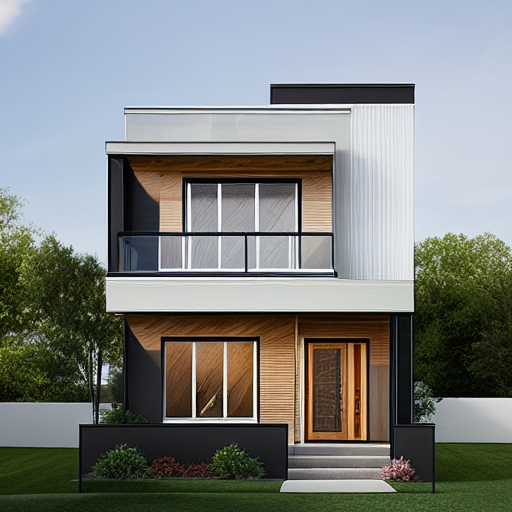

In [9]:
prompt = """
Photorealistic architectural exterior visualization of the exact
building shown in the reference sketch, modern contemporary
residential architecture, realistic concrete, glass windows,
natural stone and wood materials, professionally designed facade,
realistic daylight, detailed textures, professional architectural
photography, high quality, sharp focus.
Preserve the original building geometry, floor count, roofline,
window positions, door positions, balconies and proportions.
"""

negative_prompt = """
cartoon, illustration, painting, distorted architecture,
extra floors, missing floors, extra windows, missing windows,
deformed building, unrealistic geometry, blurry, low quality,
watermark, text, people.
"""

generator = torch.Generator(device="cpu").manual_seed(42)

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=control_image,
    width=512,
    height=512,
    num_inference_steps=20,
    guidance_scale=7.5,
    controlnet_conditioning_scale=1.0,
    generator=generator
)

generated_image = result.images[0]

generated_image.save(
    f"{OUTPUT_DIR}/first_generated_building.png"
)

print("FIRST GENERATION COMPLETE!")

display(generated_image)

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['.']


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: /content/facadeforge_outputs/01_two_storey_house_generated.png


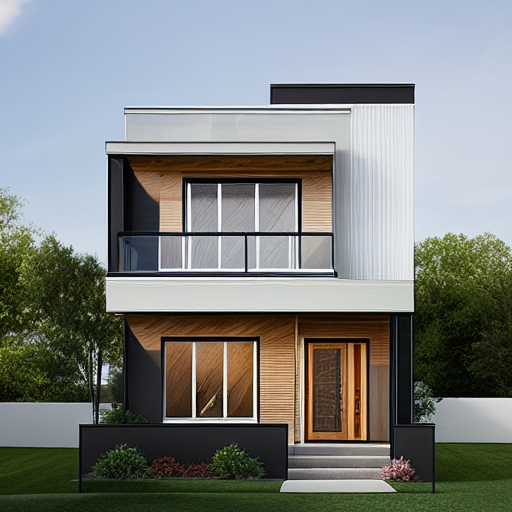

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['.']


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: /content/facadeforge_outputs/02_apartment_facade_generated.png


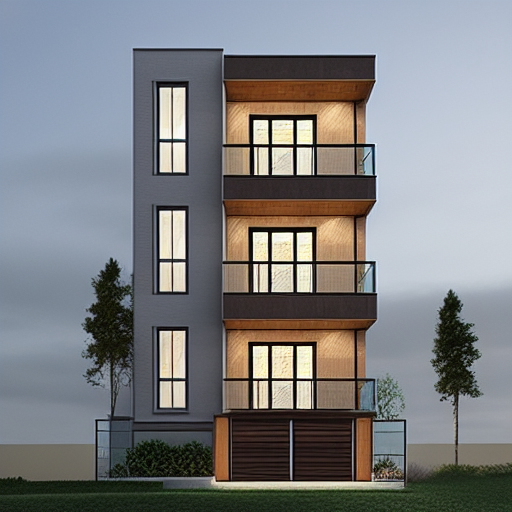

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['.']


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: /content/facadeforge_outputs/03_modern_villa_generated.png


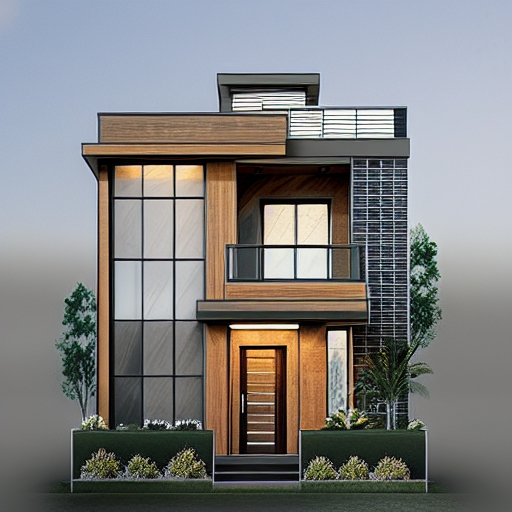

In [10]:
for index, sketch_path in enumerate(sketch_paths):

    original, control_image = prepare_sketch(sketch_path)

    generator = torch.Generator(
        device="cpu"
    ).manual_seed(42)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=control_image,
        width=512,
        height=512,
        num_inference_steps=20,
        guidance_scale=7.5,
        controlnet_conditioning_scale=1.0,
        generator=generator
    )

    output = result.images[0]

    filename = os.path.splitext(
        os.path.basename(sketch_path)
    )[0]

    output_path = os.path.join(
        OUTPUT_DIR,
        filename + "_generated.png"
    )

    output.save(output_path)

    print("Generated:", output_path)
    display(output)

In [11]:
import shutil
from google.colab import files

zip_output = shutil.make_archive(
    "/content/FacadeForge_AI_results",
    "zip",
    OUTPUT_DIR
)

files.download(zip_output)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>